In [1]:
import numpy as np 
import pandas as pd

In [2]:
df = pd.read_csv("../Set3_Admission_Predict.csv")

In [3]:
print(df.shape)
print(df.head())

(500, 9)
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        334          115                  4  3.5  5.0  9.85   
1           2        308          103                  3  2.5  3.5  7.91   
2           3        322          102                  2  4.0  3.5  8.70   
3           4        320          109                  4  3.5  2.5  8.74   
4           5        314          107                  2  3.0  3.5  7.96   

   Research  Chance of Admit  
0         1             0.97  
1         0             0.61  
2         0             0.79  
3         1             0.74  
4         0             0.61  


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

In [5]:
df

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,334,115,4,3.5,5.0,9.85,1,0.97
1,2,308,103,3,2.5,3.5,7.91,0,0.61
2,3,322,102,2,4.0,3.5,8.70,0,0.79
3,4,320,109,4,3.5,2.5,8.74,1,0.74
4,5,314,107,2,3.0,3.5,7.96,0,0.61
...,...,...,...,...,...,...,...,...,...
495,496,318,115,3,4.5,4.0,8.99,1,0.84
496,497,329,119,4,3.5,4.5,9.33,1,0.86
497,498,318,108,5,2.5,3.0,8.38,0,0.68
498,499,316,101,3,2.0,1.5,7.73,1,0.57


In [6]:
df = df.drop('Serial No.', axis=1) 

In [7]:
df['Admit'] = (df['Chance of Admit'] >= 0.75).astype(int)  

In [8]:
df

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,334,115,4,3.5,5.0,9.85,1,0.97,1
1,308,103,3,2.5,3.5,7.91,0,0.61,0
2,322,102,2,4.0,3.5,8.70,0,0.79,1
3,320,109,4,3.5,2.5,8.74,1,0.74,0
4,314,107,2,3.0,3.5,7.96,0,0.61,0
...,...,...,...,...,...,...,...,...,...
495,318,115,3,4.5,4.0,8.99,1,0.84,1
496,329,119,4,3.5,4.5,9.33,1,0.86,1
497,318,108,5,2.5,3.0,8.38,0,0.68,0
498,316,101,3,2.0,1.5,7.73,1,0.57,0


In [22]:
X = df.drop(['Chance of Admit','Admit'], axis=1)
y = df['Admit']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
                                    X, y, test_size=0.2, random_state=42)

In [31]:
rows = []
for d in [2, 3, 4, 5, 6, None]:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    tr = dt.score(X_train, y_train)
    te = dt.score(X_test, y_test)
    rows.append([str(d), round(tr, 4), round(te, 10), round(tr - te, 4)])

res = pd.DataFrame(rows, columns=['max_depth', 'Train Acc', 'Test Acc', 'Gap'])
print(res)
print("********************")
print(res.to_string(index=False))
print("********************")
print(res)

  max_depth  Train Acc  Test Acc     Gap
0         2     0.8600      0.86  0.0000
1         3     0.8775      0.89 -0.0125
2         4     0.9000      0.89  0.0100
3         5     0.9200      0.86  0.0600
4         6     0.9425      0.84  0.1025
5      None     1.0000      0.85  0.1500
********************
max_depth  Train Acc  Test Acc     Gap
        2     0.8600      0.86  0.0000
        3     0.8775      0.89 -0.0125
        4     0.9000      0.89  0.0100
        5     0.9200      0.86  0.0600
        6     0.9425      0.84  0.1025
     None     1.0000      0.85  0.1500
********************
  max_depth  Train Acc  Test Acc     Gap
0         2     0.8600      0.86  0.0000
1         3     0.8775      0.89 -0.0125
2         4     0.9000      0.89  0.0100
3         5     0.9200      0.86  0.0600
4         6     0.9425      0.84  0.1025
5      None     1.0000      0.85  0.1500


In [32]:
best = res.loc[res['Test Acc'].idxmax()]      # row with the highest test accuracy
print(best)

best_depth = None if best['max_depth'] == 'None' else int(best['max_depth'])
print("\nBest max_depth:", best_depth)

max_depth         3
Train Acc    0.8775
Test Acc       0.89
Gap         -0.0125
Name: 1, dtype: object

Best max_depth: 3


In [33]:
dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt.fit(X_train, y_train)          # trees use the UNSCALED data
pred = dt.predict(X_test)

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1-score :", round(f1_score(y_test, pred), 4))

Accuracy : 0.89
Precision: 0.8913
Recall   : 0.8723
F1-score : 0.8817


In [35]:
cm = confusion_matrix(y_test, pred)
print(cm)

[[48  5]
 [ 6 41]]


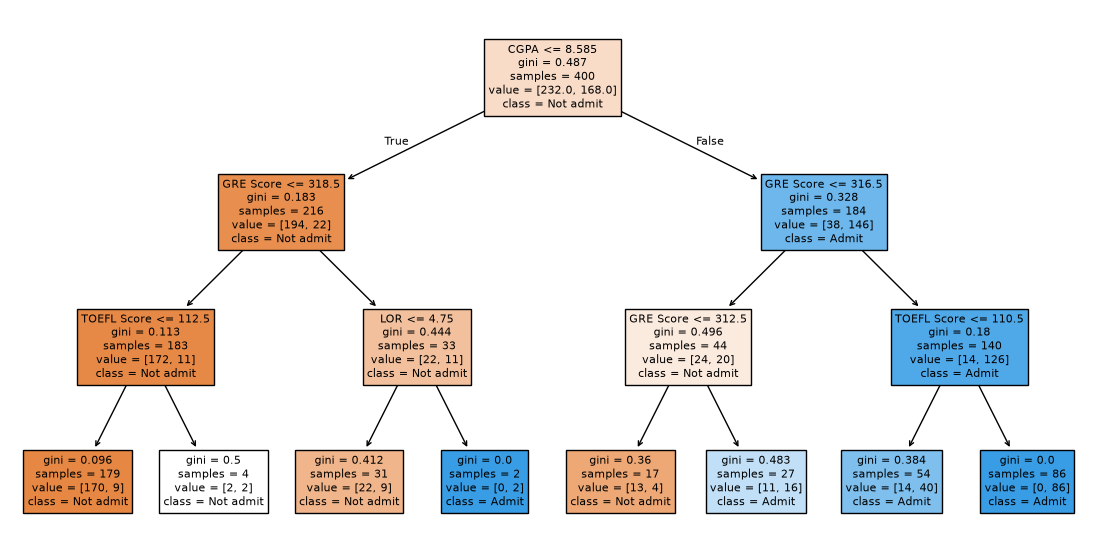

In [29]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 7))
plot_tree(dt, feature_names=X.columns, class_names=['Not admit', 'Admit'], filled=True)
plt.show()

In [36]:
#for set 3 it also involves svm so SVM part of the question:

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../Set3_Admission_Predict.csv')
print(df.shape)
print(df.isna().sum().sum(), df.duplicated().sum())     # missing values, duplicates

df = df.drop('Serial No.', axis=1)                       # ID column, not a feature
df['Admit'] = (df['Chance of Admit'] >= 0.75).astype(int)   # 1 = admitted, 0 = not

X = df.drop(['Chance of Admit', 'Admit'], axis=1)
y = df['Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


(500, 9)
0 0


In [43]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

In [44]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for k in ['linear', 'poly', 'rbf']:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)

    rows.append([k,
                 round(model.score(X_train_s, y_train), 4),
                 round(accuracy_score(y_test, pred), 4),
                 round(precision_score(y_test, pred), 4),
                 round(recall_score(y_test, pred), 4),
                 round(f1_score(y_test, pred), 4)])

res = pd.DataFrame(rows, columns=['Kernel', 'Train Acc', 'Test Acc', 'Precision', 'Recall', 'F1'])
print(res.to_string(index=False))

Kernel  Train Acc  Test Acc  Precision  Recall     F1
linear     0.8950      0.85     0.8182  0.8372 0.8276
  poly     0.8825      0.83     0.8611  0.7209 0.7848
   rbf     0.9125      0.84     0.8293  0.7907 0.8095


In [46]:
rows = []
for C in [0.1, 1, 10, 100]:
    model = SVC(kernel='linear', C=C)
    model.fit(X_train_s, y_train)
    rows.append([C, round(model.score(X_train_s, y_train), 4),
                 round(model.score(X_test_s, y_test), 4)])

print(pd.DataFrame(rows, columns=['C', 'Train Acc', 'Test Acc'])
    .to_string(index=False))

    C  Train Acc  Test Acc
  0.1     0.8950      0.86
  1.0     0.8950      0.85
 10.0     0.8975      0.85
100.0     0.8975      0.85


In [50]:
rows = []
for C in [0.1, 1, 10, 100]:
    for g in [0.001, 0.01, 0.1, 1]:
        model = SVC(kernel='rbf', C=C, gamma=g)
        model.fit(X_train_s, y_train)
        tr = model.score(X_train_s, y_train)
        te = model.score(X_test_s, y_test)
        rows.append([C, g, round(tr, 4), round(te, 4), round(tr - te, 4)])

grid = pd.DataFrame(rows, columns=['C', 'gamma', 'Train Acc', 'Test Acc', 'Gap'])
print(grid.to_string(index=False))
print('\n')
# test accuracy as a table: rows = C, columns = gamma
print(grid.pivot(index='C', columns='gamma', values='Test Acc'))

# best configuration = highest test accuracy
i = grid['Test Acc'].idxmax()
best_C = grid['C'][i]
best_gamma = grid['gamma'][i]

print('\n')
print("Best: C =", best_C, " gamma =", best_gamma, " Test Acc =", grid['Test Acc'][i])

    C  gamma  Train Acc  Test Acc    Gap
  0.1  0.001     0.5700      0.57 0.0000
  0.1  0.010     0.8600      0.82 0.0400
  0.1  0.100     0.8875      0.85 0.0375
  0.1  1.000     0.5900      0.57 0.0200
  1.0  0.001     0.8600      0.84 0.0200
  1.0  0.010     0.9000      0.85 0.0500
  1.0  0.100     0.9025      0.85 0.0525
  1.0  1.000     0.9725      0.77 0.2025
 10.0  0.001     0.8950      0.85 0.0450
 10.0  0.010     0.8925      0.85 0.0425
 10.0  0.100     0.9475      0.84 0.1075
 10.0  1.000     1.0000      0.75 0.2500
100.0  0.001     0.8950      0.85 0.0450
100.0  0.010     0.9025      0.87 0.0325
100.0  0.100     0.9750      0.81 0.1650
100.0  1.000     1.0000      0.75 0.2500


gamma  0.001  0.010  0.100  1.000
C                                
0.1     0.57   0.82   0.85   0.57
1.0     0.84   0.85   0.85   0.77
10.0    0.85   0.85   0.84   0.75
100.0   0.85   0.87   0.81   0.75


Best: C = 100.0  gamma = 0.01  Test Acc = 0.87


In [51]:

# ---- best SVM (uses SCALED data) ----
svm = SVC(kernel='linear', C=best_C, gamma=best_gamma)
svm.fit(X_train_s, y_train)
svm_pred = svm.predict(X_test_s)

# ---- best Decision Tree (uses UNSCALED data) ----
dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# ---- comparison table ----
def make_row(name, config, pred):
    return [name, config,
            round(accuracy_score(y_test, pred), 4),
            round(precision_score(y_test, pred), 4),
            round(recall_score(y_test, pred), 4),
            round(f1_score(y_test, pred), 4)]

comp = pd.DataFrame([make_row('SVM', 'RBF, C=100, gamma=0.01', svm_pred),
                     make_row('Decision Tree', 'max_depth=3', dt_pred)],
                    columns=['Model', 'Configuration', 'Accuracy', 'Precision', 'Recall', 'F1'])
print(comp.to_string(index=False))

# ---- confusion matrices ----
print("SVM confusion matrix:")
print(confusion_matrix(y_test, svm_pred))
print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, dt_pred))

        Model          Configuration  Accuracy  Precision  Recall     F1
          SVM RBF, C=100, gamma=0.01      0.87     0.8261  0.8837 0.8539
Decision Tree            max_depth=3      0.84     0.8462  0.7674 0.8049
SVM confusion matrix:
[[49  8]
 [ 5 38]]
Decision Tree confusion matrix:
[[51  6]
 [10 33]]


In [52]:
#winner svm on basis of f1_score and Recall

In [ ]:
6. Explain the role of the kernel function in SVM.

